# 01 - Exploratory data analysis

Dataset built by `scripts/transform.py`: one row per (stock, day) with ~190 numeric features,
10 categorical features and the targets. Questions:
1. How much data is there per market and over time (and how much is tradable)?
2. What does the target look like (`is_outperform_20d`, `excess_future_20d`)?
3. Which features are related to the target (correlations, deciles, categories)?

In [1]:
import sys
sys.path.insert(0, "..")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

import config as cfg
from scripts.transform import CATEGORICAL, FEATURE_SETS, NUMERIC

pd.set_option("display.width", 160)
sns.set_theme(style="whitegrid")
IMG = cfg.ROOT / "images"
IMG.mkdir(exist_ok=True)

cols = ["Date", "Ticker", "Market", "Sector", "is_liquid", "growth_future_20d", "excess_future_20d",
        "is_outperform_20d", "is_positive_growth_20d"] + NUMERIC + [c for c in CATEGORICAL if c not in ("Market", "Sector")]
df = pd.read_parquet(cfg.PROCESSED_DIR / "dataset.parquet", columns=list(dict.fromkeys(cols)))
print(df.shape)
print({k: len(v) for k, v in FEATURE_SETS.items()})

(937505, 210)
{'GROWTH': 8, 'TECHNICAL': 14, 'TALIB': 29, 'PATTERNS': 61, 'RELATIVE': 10, 'CROSS': 10, 'MARKET': 55, 'MACRO': 6}


## 1. Coverage: stocks per market and liquid universe

In [2]:
cov = df.groupby("Market").agg(rows=("Ticker", "size"), tickers=("Ticker", "nunique"),
                               liquid_share=("is_liquid", "mean"), first_date=("Date", "min"))
cov

,rows,tickers,liquid_share,first_date
Market,,,,
AN,31352,7,0.881953,2005-01-03
AR,76891,18,0.698222,2005-01-03
BR,528309,147,0.781986,2005-01-03
CL,139035,30,0.510720,2005-01-03
MX,161918,36,0.857230,2005-01-03


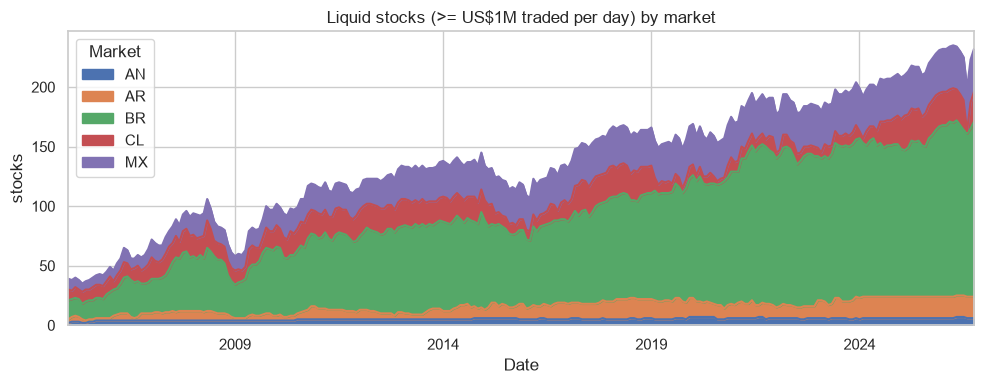

In [3]:
liquid = df[df["is_liquid"] == 1]
n = liquid.groupby([pd.Grouper(key="Date", freq="ME"), "Market"])["Ticker"].nunique().unstack()
ax = n.plot.area(figsize=(10, 4), title="Liquid stocks (>= US$1M traded per day) by market")
ax.set_ylabel("stocks"); plt.tight_layout(); plt.savefig(IMG / "eda_universe.png", dpi=110); plt.show()

The tradable universe grows from 55 stocks in 2005 to ~235 in 2026, mostly in Brazil (part of it is
survivorship: today's index members were smaller or not listed 20 years ago). Chile has a known target from
2007-11 (ECH ETF) and Argentina from 2011-03 (ARGT ETF): the target needs the country ETF.

## 2. Targets

In [4]:
k = liquid[liquid["is_outperform_20d"] >= 0]
print("rows with a known target:", len(k))
k.groupby("Market")[["is_outperform_20d", "is_positive_growth_20d", "excess_future_20d"]].mean().round(3)

rows with a known target: 684999


,is_outperform_20d,is_positive_growth_20d,excess_future_20d
Market,,,
AN,0.519,0.558,0.007
AR,0.480,0.510,0.003
BR,0.492,0.516,0.003
CL,0.499,0.523,0.001
MX,0.506,0.544,0.004


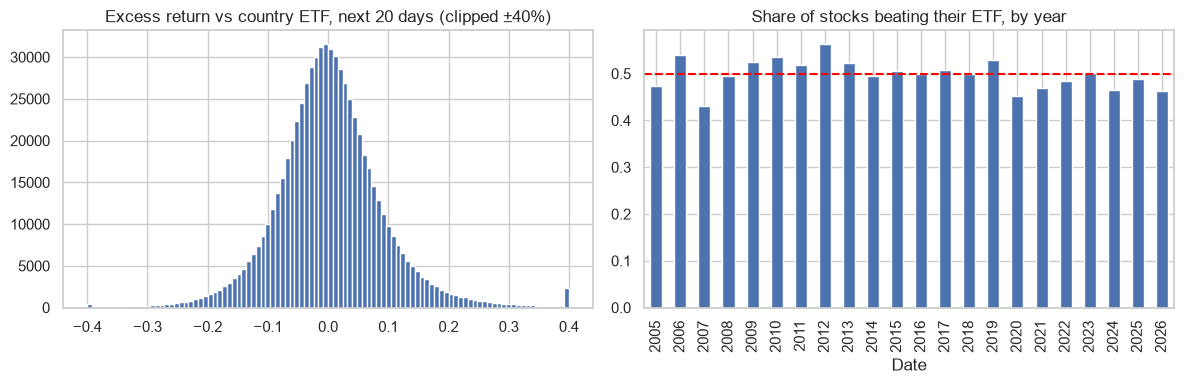

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
k["excess_future_20d"].clip(-0.4, 0.4).hist(bins=100, ax=axes[0])
axes[0].set_title("Excess return vs country ETF, next 20 days (clipped ±40%)")
k.groupby(k["Date"].dt.year)["is_outperform_20d"].mean().plot.bar(ax=axes[1], title="Share of stocks beating their ETF, by year")
axes[1].axhline(0.5, color="red", ls="--")
plt.tight_layout(); plt.savefig(IMG / "eda_target.png", dpi=110); plt.show()

- The target is balanced (~49% positive): beating the country ETF is close to a coin flip, as expected
  (the ETF is cap-weighted and dominated by the largest stocks).
- The excess return has fat tails (±40%): a few large winners/losers dominate the P&L of a strategy,
  so precision alone is not enough - the simulation must check returns.
- The share of winners moves with the year (e.g. 2020-2021 small caps lagged the large caps): this is a
  regime effect that the model can only partly learn.

## 3. Correlation of features with the target
Spearman (rank) correlation with the 20-day excess return, robust to outliers.

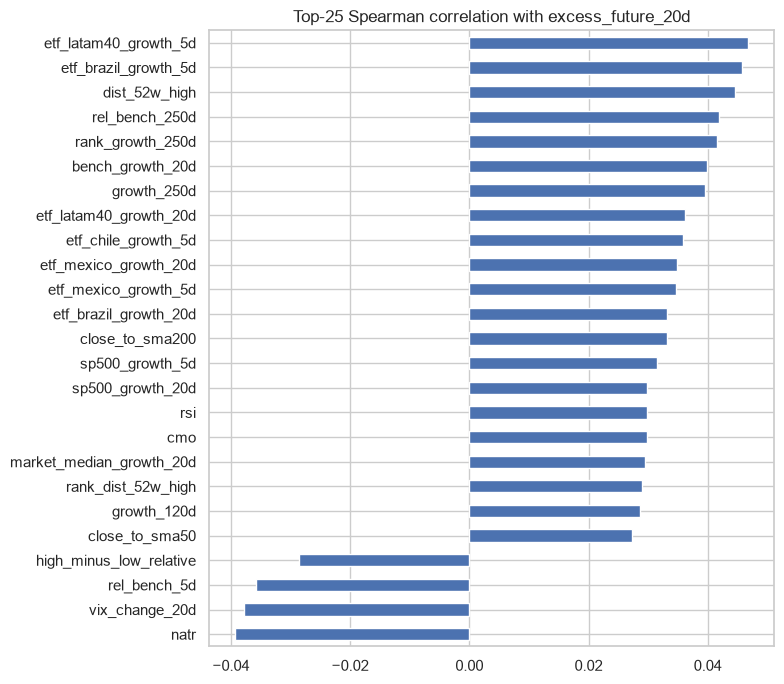

etf_latam40_growth_5d       0.0468
etf_brazil_growth_5d        0.0457
dist_52w_high               0.0446
rel_bench_250d              0.0418
rank_growth_250d            0.0416
bench_growth_20d            0.0398
growth_250d                 0.0395
natr                       -0.0394
vix_change_20d             -0.0377
etf_latam40_growth_20d      0.0361
etf_chile_growth_5d         0.0358
rel_bench_5d               -0.0357
etf_mexico_growth_20d       0.0349
etf_mexico_growth_5d        0.0347
etf_brazil_growth_20d       0.0332
close_to_sma200             0.0332
sp500_growth_5d             0.0315
sp500_growth_20d            0.0298
rsi                         0.0297
cmo                         0.0297
market_median_growth_20d    0.0294
rank_dist_52w_high          0.0290
growth_120d                 0.0287
high_minus_low_relative    -0.0285
close_to_sma50              0.0274
dtype: float64

In [6]:
sample = k.sample(200_000, random_state=cfg.SEED)
corr = sample[NUMERIC].corrwith(sample["excess_future_20d"], method="spearman").dropna()
top = corr.reindex(corr.abs().sort_values(ascending=False).index).head(25)
ax = top.sort_values().plot.barh(figsize=(8, 7), title="Top-25 Spearman correlation with excess_future_20d")
plt.tight_layout(); plt.savefig(IMG / "eda_correlation.png", dpi=110); plt.show()
top.round(4)

Correlations are small (|ρ| < 0.05), which is normal for future returns. Three families stand out:
- **Momentum**: stocks close to their 52-week high and with a strong 12-month return relative to their ETF
  (`dist_52w_high`, `rel_bench_250d`, `rank_growth_250d`) keep outperforming.
- **Short-term reversal and volatility**: a strong last week vs the ETF (`rel_bench_5d`) and a high daily
  range / NATR are followed by underperformance.
- **Market moves**: when the region rose in the last 1-4 weeks (ETF growth 5d/20d), the average stock beats
  the cap-weighted ETF in the next month, and after a VIX spike it lags. These variables are the same for
  every stock of a day, so they describe *when* the whole universe beats the ETF, not *which* stock does.

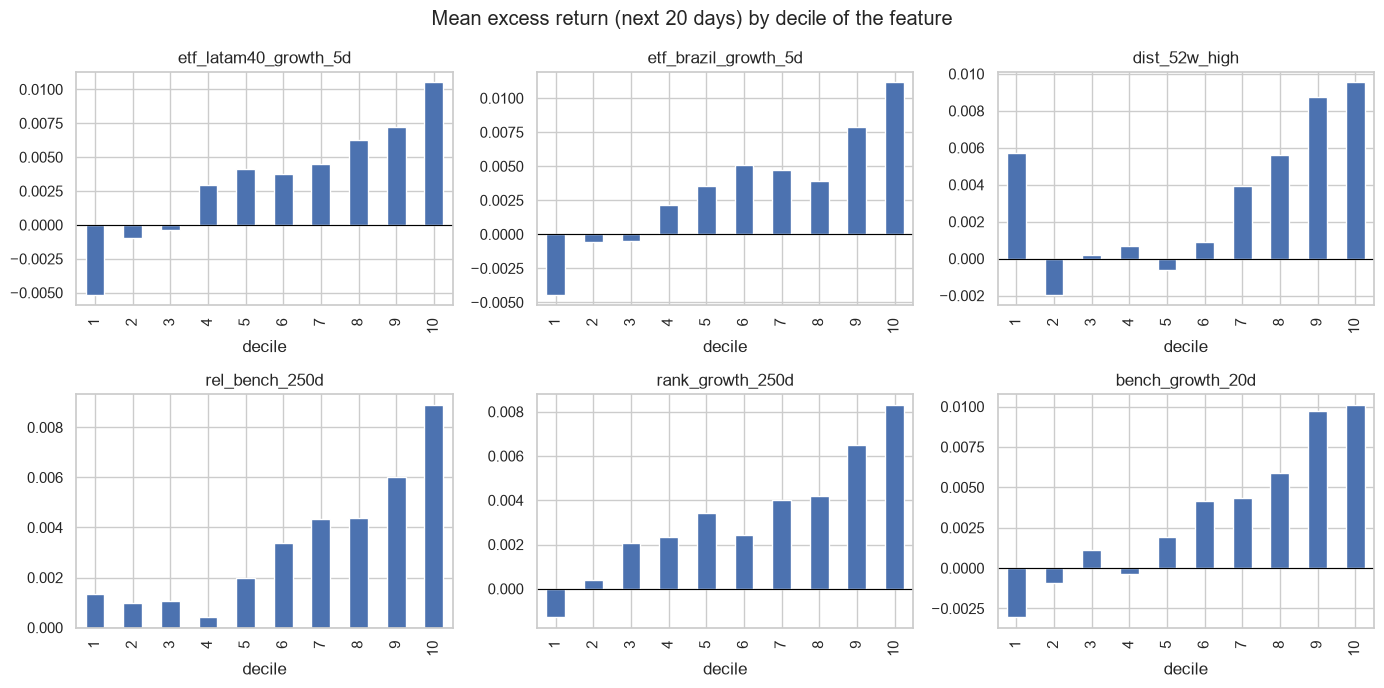

In [7]:
def decile_plot(feature, ax):
    d = sample[[feature, "excess_future_20d", "is_outperform_20d"]].dropna()
    d["decile"] = pd.qcut(d[feature].rank(method="first"), 10, labels=range(1, 11))
    d.groupby("decile", observed=True)["excess_future_20d"].mean().plot.bar(ax=ax, title=feature)
    ax.axhline(0, color="black", lw=0.8)

features = top.index[:6].tolist()
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for f, ax in zip(features, axes.ravel()):
    decile_plot(f, ax)
fig.suptitle("Mean excess return (next 20 days) by decile of the feature")
plt.tight_layout(); plt.savefig(IMG / "eda_deciles.png", dpi=110); plt.show()

## 4. Categorical features

In [8]:
for c in ["Sector", "rsi_zone", "vol_quintile", "momentum_quintile", "near_52w_high", "vix_regime", "market_regime"]:
    print(k.groupby(c)[["is_outperform_20d", "excess_future_20d"]].agg(["mean", "size"]).round(4), "\n")

                       is_outperform_20d         excess_future_20d        
                                    mean    size              mean    size
Sector                                                                    
Communication                     0.4684   20477           -0.0035   20477
Consumer Discretionary            0.4912   82880            0.0041   82880
Consumer Staples                  0.4839   76806            0.0001   76806
Energy                            0.4964   43510            0.0058   43510
Financials                        0.5166  128873            0.0054  128873
Health Care                       0.4734   32073           -0.0029   32073
Industrials                       0.5011   73114            0.0026   73114
Materials                         0.4843  100703            0.0042  100703
Other                             0.4903   21483            0.0055   21483
Real Estate                       0.5009   14379            0.0030   14379
Technology               

              is_outperform_20d         excess_future_20d        
                           mean    size              mean    size
near_52w_high                                                    
at_high                  0.5274   73760            0.0094   73760
close                    0.5144  159278            0.0063  159278
far                      0.4760  167956            0.0013  167956
mid                      0.4897  274125            0.0009  274125 

           is_outperform_20d         excess_future_20d        
                        mean    size              mean    size
vix_regime                                                    
calm                  0.5047  228892            0.0050  228892
normal                0.4951  356864            0.0029  356864
stress                0.4788   99243            0.0001   99243 

              is_outperform_20d         excess_future_20d        
                           mean    size              mean    size
market_regime           

## 5. Correlation between features (redundancy)

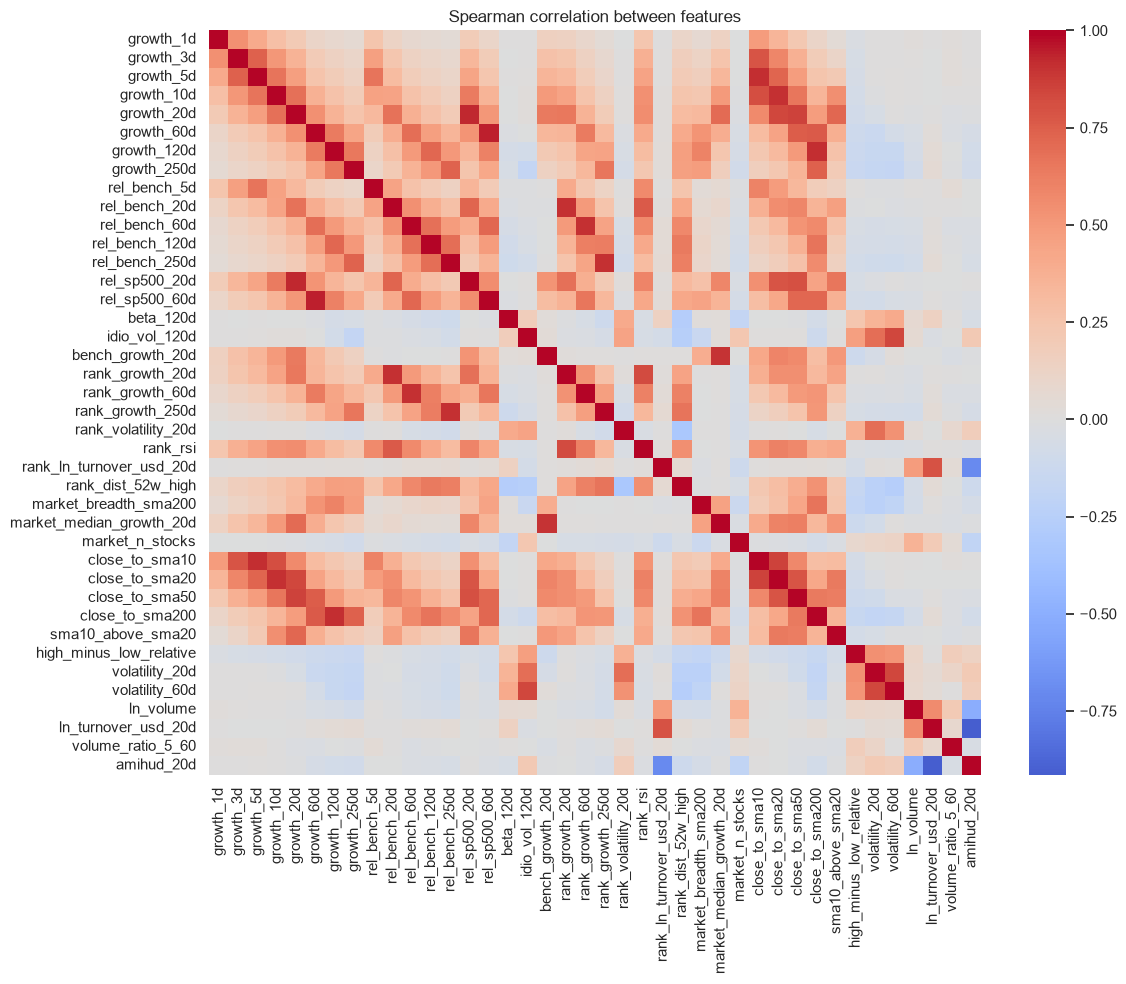

In [9]:
groups = ["GROWTH", "RELATIVE", "CROSS", "TECHNICAL"]
subset = [c for g in groups for c in FEATURE_SETS[g]][:40]
plt.figure(figsize=(12, 10))
sns.heatmap(sample[subset].corr(method="spearman"), cmap="coolwarm", center=0, xticklabels=True, yticklabels=True)
plt.title("Spearman correlation between features"); plt.tight_layout(); plt.savefig(IMG / "eda_feature_corr.png", dpi=110); plt.show()

Growth features and relative-strength features are highly correlated in the same window (the country
ETF explains part of each stock's return), so tree models will pick one of each pair. Cross-sectional
ranks are the same information normalised by day, which helps when the whole market moves.

Categorical features confirm the momentum effect: stocks in the RSI "overbought" zone (53.4% winners) and
at their 52-week high (52.7%) beat the ETF more often than those far from it (47.6%); the most volatile
quintile is the worst (47.9%); Financials and Utilities do better than Health Care and Communication;
outperformance is lower in high-VIX periods (47.9%).

**Summary**
- 937k rows (2005-2026), 239 stocks in 5 markets; 685k rows are liquid and have a known target.
- Balanced target (~49% positive); weak but consistent signals: 12-month momentum and 52-week high,
  short-term reversal, volatility, sector and market conditions.
- Data issues found and fixed in `transform.py`: Yahoo prints with no volume and broken split adjustments
  in illiquid years (56k rows removed) and a CLP=X FX glitch that made all Chilean stocks jump ×100.